In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.tree import DecisionTreeClassifier, plot_tree

In [3]:
DATA_DIR = Path("data")
if not (DATA_DIR / "train.csv").is_file():
    sibling_data_dirs = [
        path.parent / "data"
        for path in Path.cwd().rglob("TH1.ipynb")
        if (path.parent / "data" / "train.csv").is_file()
    ]
    if len(sibling_data_dirs) != 1:
        raise FileNotFoundError(
            "Could not uniquely find the data folder beside TH1.ipynb. "
            "Run this notebook from its folder or update DATA_DIR."
        )
    DATA_DIR = sibling_data_dirs[0]

required_files = ["train.csv", "test.csv", "gender_submission.csv"]
missing_files = [name for name in required_files if not (DATA_DIR / name).is_file()]
if missing_files:
    raise FileNotFoundError(f"Missing data files in {DATA_DIR}: {missing_files}")

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")
gender_template = pd.read_csv(DATA_DIR / "gender_submission.csv")

numeric_features = ["Pclass", "Age", "SibSp", "Parch", "Fare"]
categorical_features = ["Sex", "Embarked"]
features = numeric_features + categorical_features

required_train_columns = features + ["PassengerId", "Survived"]
required_test_columns = features + ["PassengerId"]
if missing := set(required_train_columns) - set(train_df.columns):
    raise ValueError(f"train.csv is missing columns: {sorted(missing)}")
if missing := set(required_test_columns) - set(test_df.columns):
    raise ValueError(f"test.csv is missing columns: {sorted(missing)}")
if not {"PassengerId", "Survived"}.issubset(gender_template.columns):
    raise ValueError("gender_submission.csv must contain PassengerId and Survived")
if not train_df["PassengerId"].is_unique or not test_df["PassengerId"].is_unique:
    raise ValueError("PassengerId values must be unique in train.csv and test.csv")
if not gender_template["PassengerId"].is_unique:
    raise ValueError("PassengerId values must be unique in gender_submission.csv")
if set(test_df["PassengerId"]) != set(gender_template["PassengerId"]):
    raise ValueError("test.csv and gender_submission.csv must contain the same passengers")
if train_df["Survived"].isna().any():
    raise ValueError("train.csv contains missing Survived labels")

X = train_df[features]
y = train_df["Survived"]
print(f"Training rows: {len(train_df)}; test rows: {len(test_df)}")
train_df.head()

Training rows: 891; test rows: 418


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [4]:
preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", SimpleImputer(strategy="median"), numeric_features),
        (
            "categorical",
            Pipeline(
                steps=[
                    ("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore")),
                ]
            ),
            categorical_features,
        ),
    ]
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

dt_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", DecisionTreeClassifier(random_state=42)),
    ]
)
dt_params = {"classifier__max_depth": [1, 2, 4, 6, 8, 10, None]}
cv_dt = GridSearchCV(
    dt_pipeline,
    param_grid=dt_params,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
cv_dt.fit(X, y)
print("Best decision-tree parameters:", cv_dt.best_params_)
print(f"Best mean CV ROC AUC: {cv_dt.best_score_:.3f}")

Best decision-tree parameters: {'classifier__max_depth': 4}
Best mean CV ROC AUC: 0.844


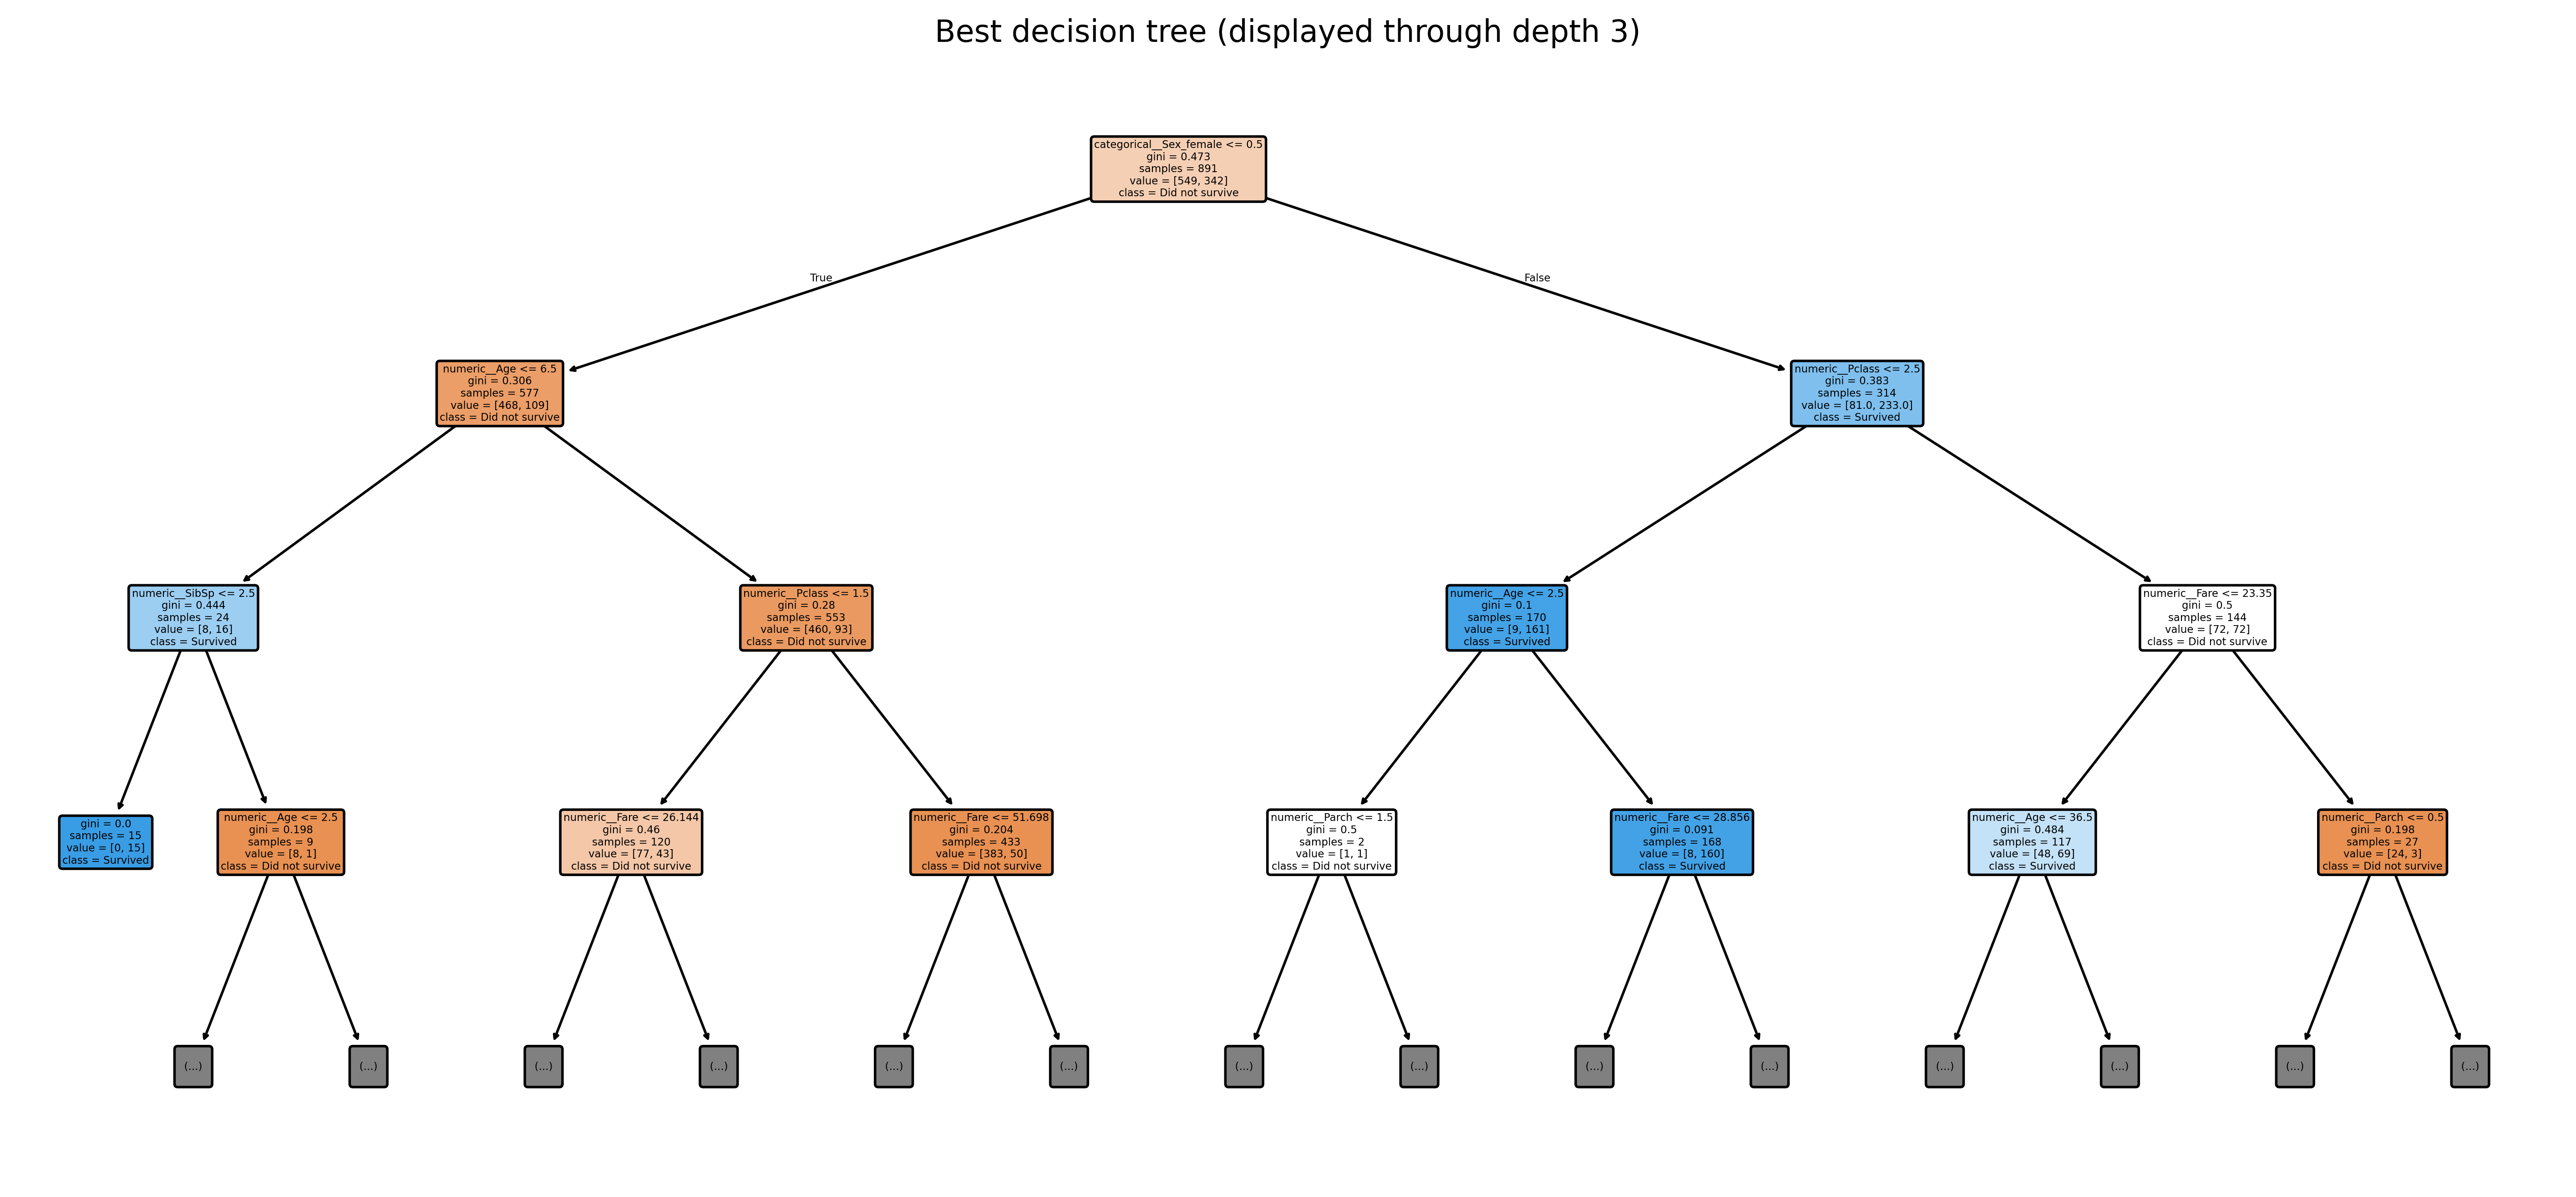

In [5]:
best_dt = cv_dt.best_estimator_
feature_names = best_dt.named_steps["preprocessor"].get_feature_names_out()
plt.figure(figsize=(18, 8))
plot_tree(
    best_dt.named_steps["classifier"],
    feature_names=feature_names,
    class_names=["Did not survive", "Survived"],
    filled=True,
    rounded=True,
    max_depth=3,
)
plt.title("Best decision tree (displayed through depth 3)")
plt.show()

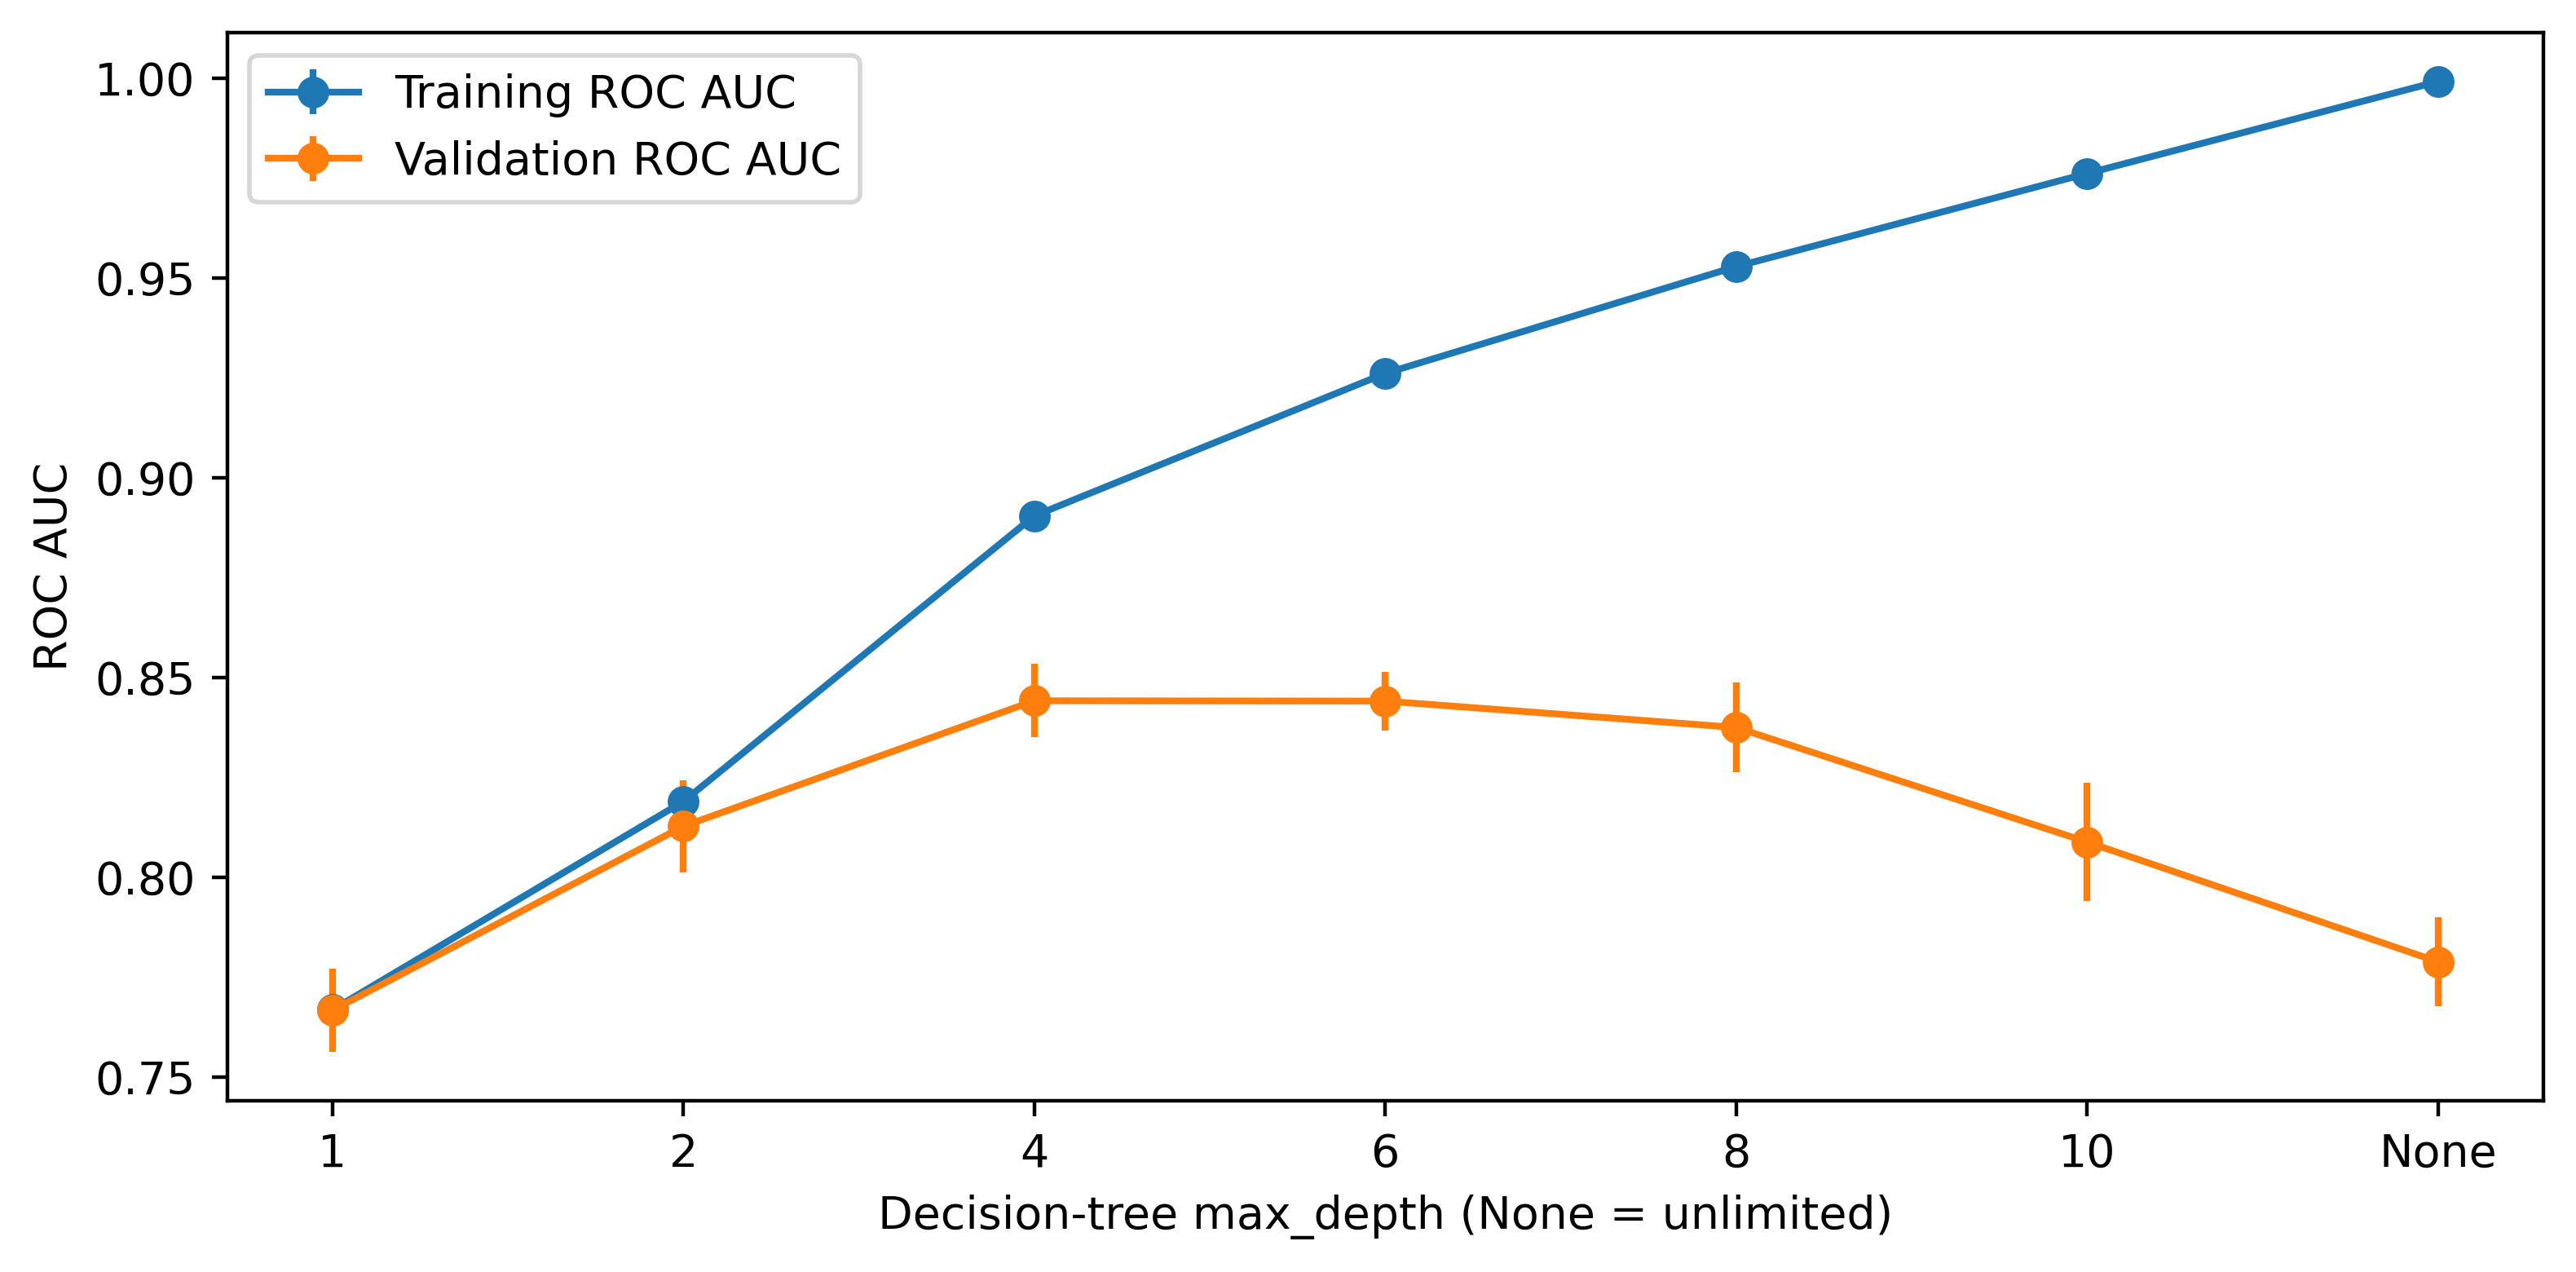

In [6]:
dt_results = pd.DataFrame(cv_dt.cv_results_)
depth_labels = [str(depth) for depth in dt_results["param_classifier__max_depth"]]
plt.figure(figsize=(8, 4))
plt.errorbar(
    depth_labels,
    dt_results["mean_train_score"],
    yerr=dt_results["std_train_score"] / np.sqrt(cv.get_n_splits()),
    marker="o",
    label="Training ROC AUC",
)
plt.errorbar(
    depth_labels,
    dt_results["mean_test_score"],
    yerr=dt_results["std_test_score"] / np.sqrt(cv.get_n_splits()),
    marker="o",
    label="Validation ROC AUC",
)
plt.xlabel("Decision-tree max_depth (None = unlimited)")
plt.ylabel("ROC AUC")
plt.legend()
plt.tight_layout()
plt.show()

In [7]:
rf_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            RandomForestClassifier(random_state=42, n_jobs=1),
        ),
    ]
)
rf_params = {"classifier__n_estimators": list(range(10, 110, 10))}
cv_rf_ex = GridSearchCV(
    rf_pipeline,
    param_grid=rf_params,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    return_train_score=True,
)
cv_rf_ex.fit(X, y)
print("Best random-forest parameters:", cv_rf_ex.best_params_)
print(f"Best mean CV ROC AUC: {cv_rf_ex.best_score_:.3f}")

Best random-forest parameters: {'classifier__n_estimators': 100}
Best mean CV ROC AUC: 0.872


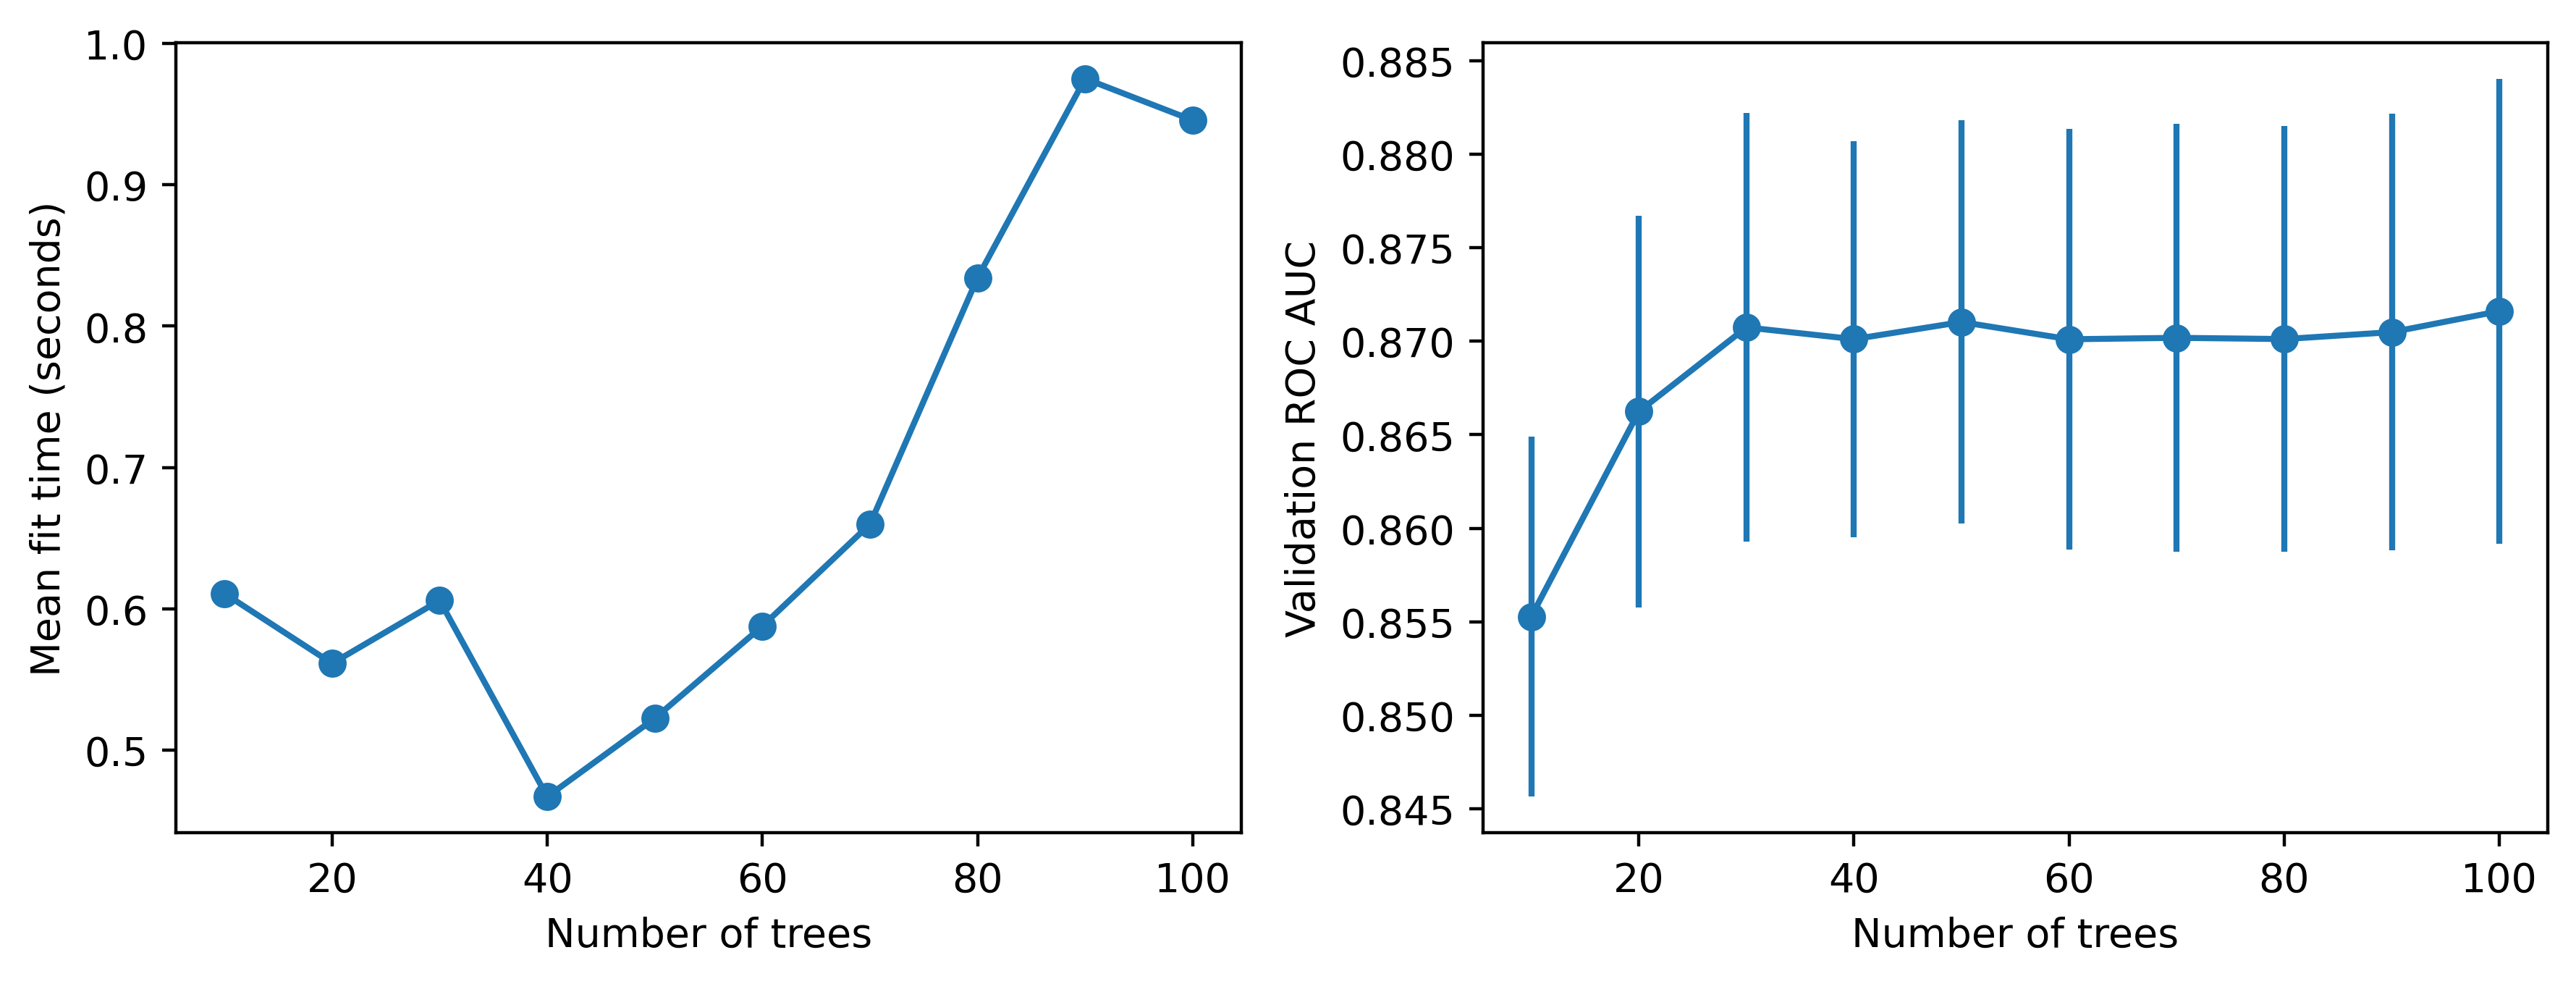

In [8]:
rf_results = pd.DataFrame(cv_rf_ex.cv_results_)
fig, axs = plt.subplots(nrows=1, ncols=2, figsize=(9, 3.5))
axs[0].plot(
    rf_results["param_classifier__n_estimators"],
    rf_results["mean_fit_time"],
    "-o",
)
axs[0].set_xlabel("Number of trees")
axs[0].set_ylabel("Mean fit time (seconds)")
axs[1].errorbar(
    rf_results["param_classifier__n_estimators"],
    rf_results["mean_test_score"],
    yerr=rf_results["std_test_score"] / np.sqrt(cv.get_n_splits()),
    marker="o",
)
axs[1].set_xlabel("Number of trees")
axs[1].set_ylabel("Validation ROC AUC")
plt.tight_layout()
plt.show()

Best random-forest parameters: {'classifier__n_estimators': 100}


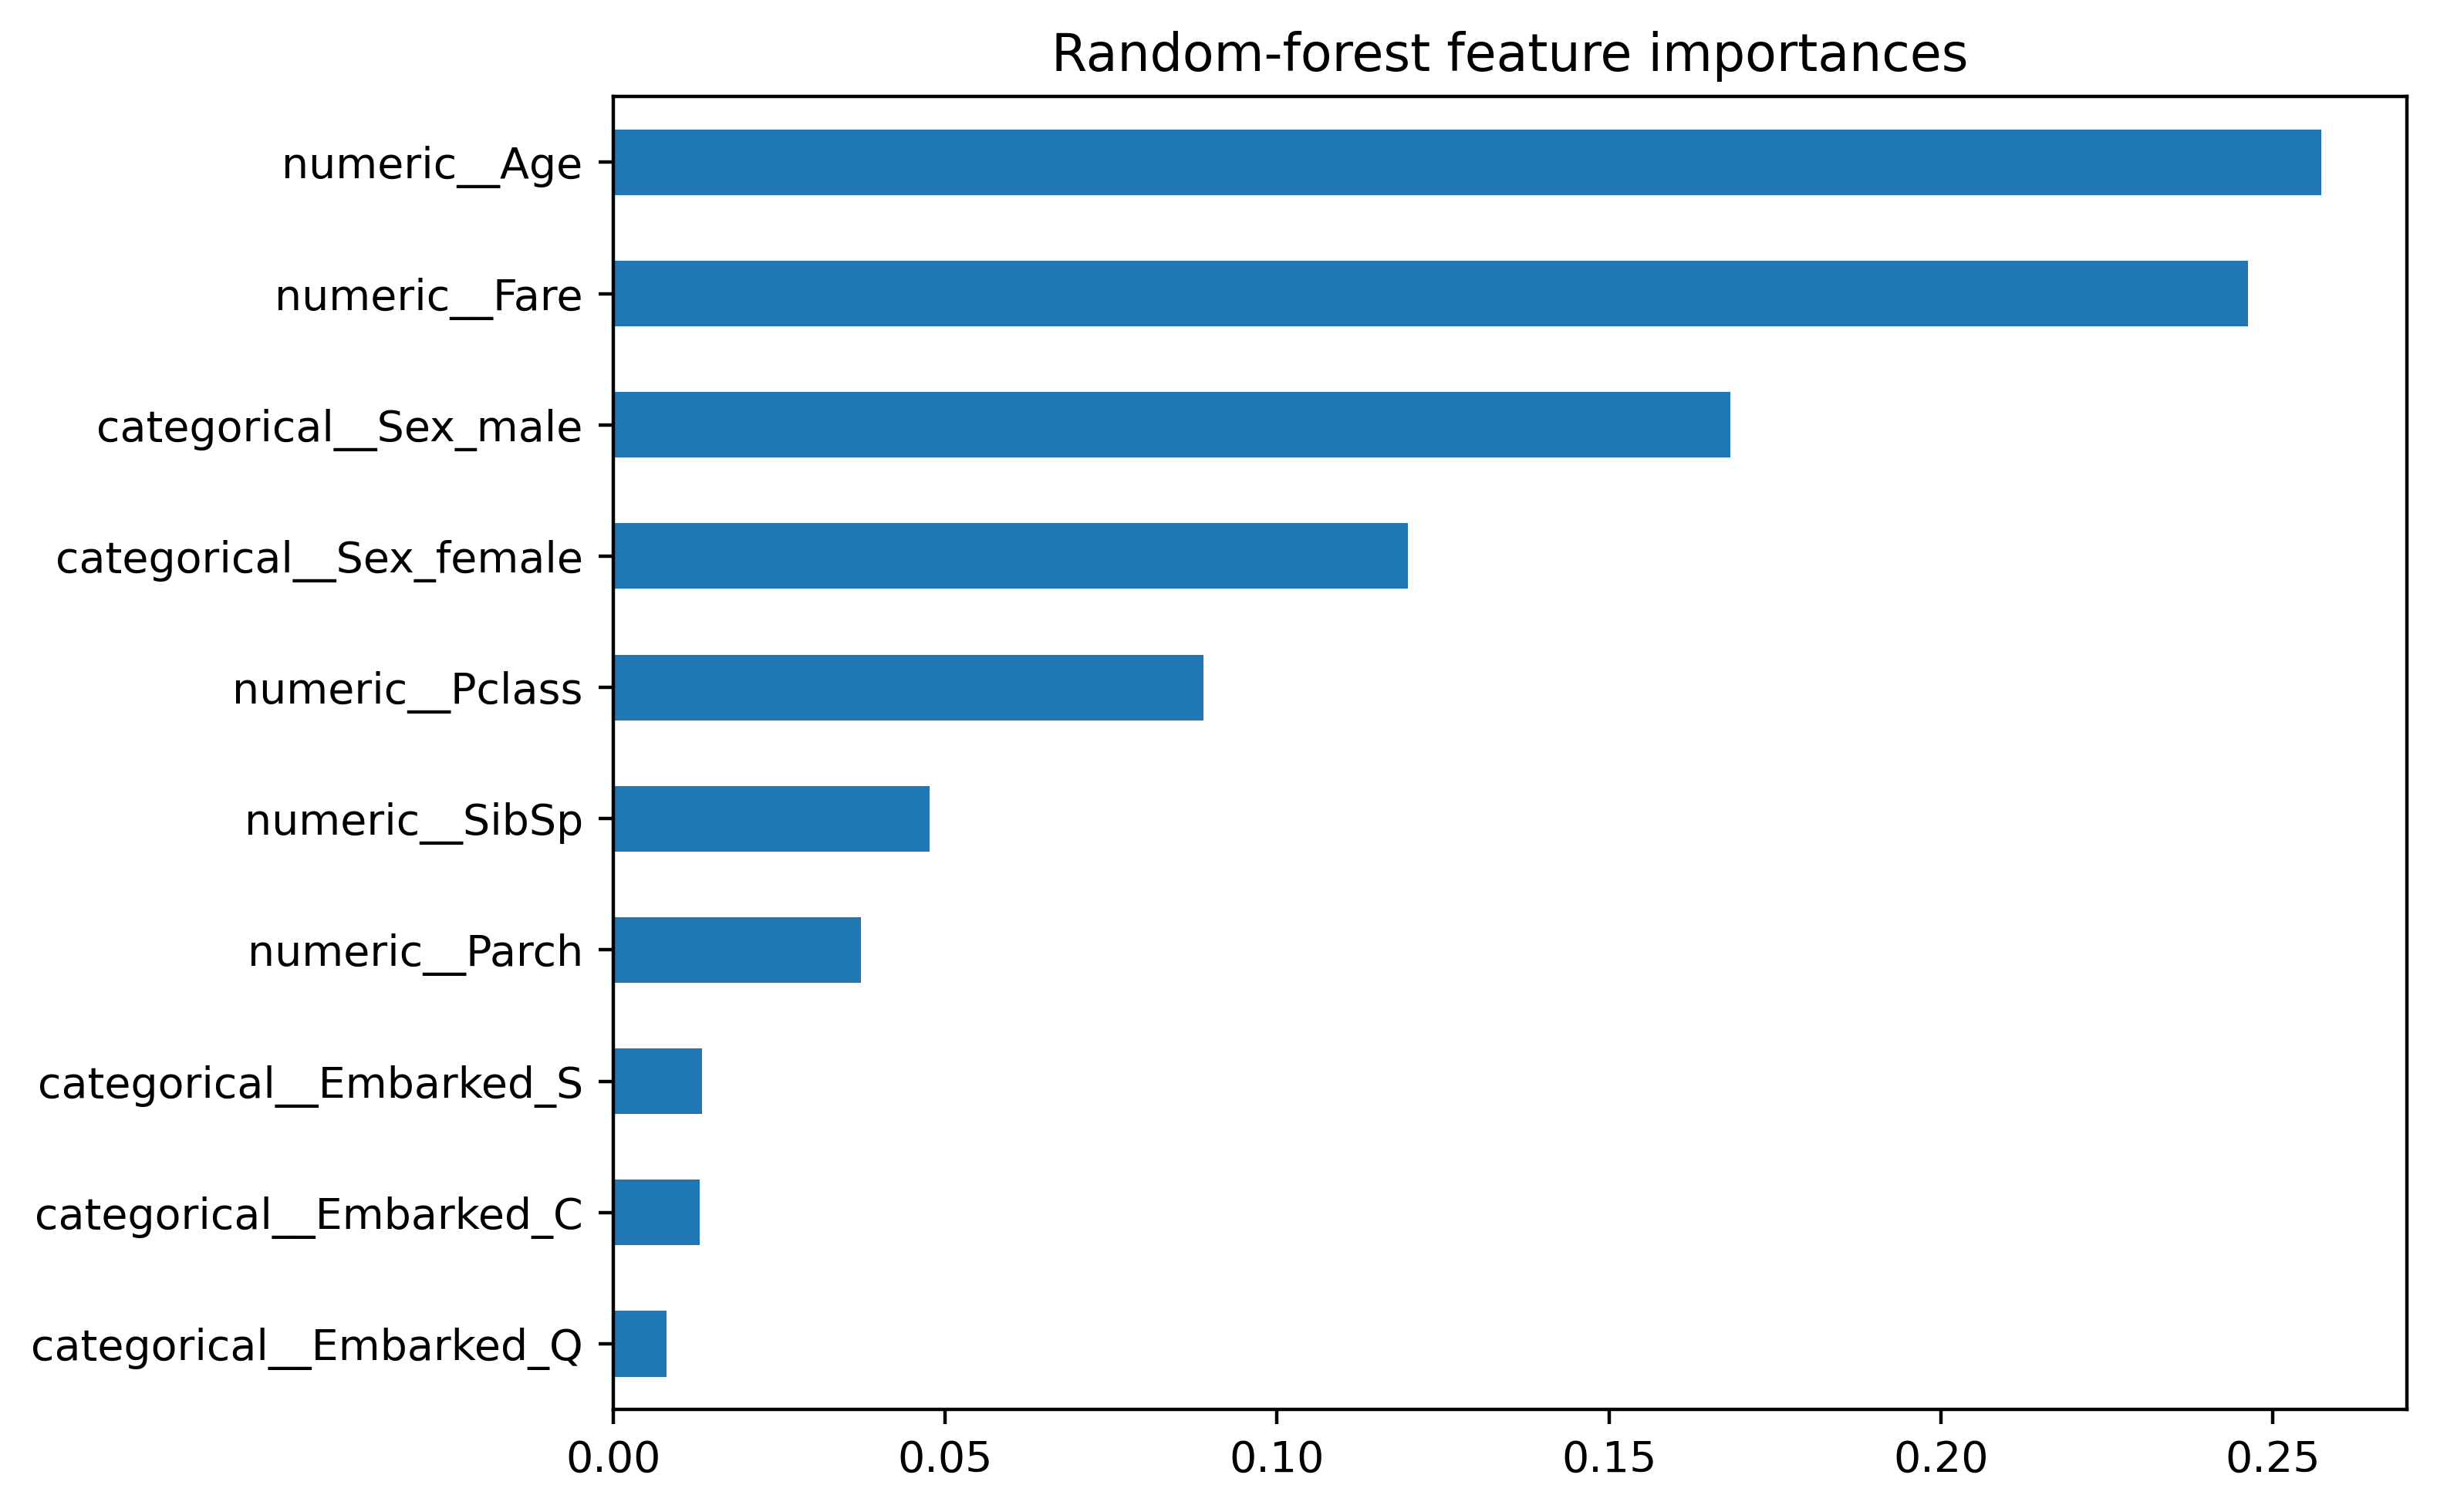

Saved 418 predictions to data\submission.csv


,PassengerId,Survived
0,892,0
1,893,0
2,894,0
3,895,1
4,896,0


In [9]:
best_rf = cv_rf_ex.best_estimator_
print("Best random-forest parameters:", cv_rf_ex.best_params_)

feature_names = best_rf.named_steps["preprocessor"].get_feature_names_out()
feature_importances = pd.Series(
    best_rf.named_steps["classifier"].feature_importances_,
    index=feature_names,
    name="Importance",
).sort_values()
feature_importances.plot.barh(figsize=(8, 5))
plt.title("Random-forest feature importances")
plt.tight_layout()
plt.show()

# gender_submission.csv is a submission template, not ground-truth test labels.
test_predictions = best_rf.predict(test_df[features])
predictions = pd.DataFrame(
    {"PassengerId": test_df["PassengerId"], "Survived": test_predictions}
)
submission = gender_template[["PassengerId"]].merge(
    predictions,
    on="PassengerId",
    how="left",
    validate="one_to_one",
)
if submission["Survived"].isna().any():
    raise ValueError("Some template PassengerId values did not receive predictions")
submission["Survived"] = submission["Survived"].astype(int)
submission_path = DATA_DIR / "submission.csv"
submission.to_csv(submission_path, index=False)
print(f"Saved {len(submission)} predictions to {submission_path}")
submission.head()